# Graphs 3: Colorings, orderings and real networks

*Learning path: graphs and networks, part 3 of 3.* [Index](README.md) · Previous: [Shortest paths, trees, flows and matchings](02-paths-trees-and-flows.ipynb)

A university must schedule its exams so that no student has two at the same time, using as few time slots as
possible. A student wants to take courses in an order that respects every prerequisite. A historian asks why one
family, the Medici, came to rule Florence, and a search engine must decide which of a billion pages to show first.
All four are graph questions, and this lesson answers them: with colorings, orderings, and measures of how central
a vertex is. It ends with random graphs, and the surprisingly sudden moment when a random network becomes connected.

**Who this is for.** Students who have done [lesson 1](01-graphs-and-tours.ipynb); lesson 2 helps for section 3.

**What you will be able to do afterwards:**

1. turn a scheduling problem into a graph coloring, and find the chromatic number;
2. count colorings with the chromatic polynomial;
3. order tasks with prerequisites (topological sorting);
4. measure the importance of a vertex by betweenness and PageRank;
5. simulate random graphs and see a threshold.

Plan about 60 minutes. Each section ends with a **Try this**; exercises, hints and answers are at the end.

## 1. Scheduling exams by coloring

Eight exams; an edge joins two exams that some student takes both of, so they need different time slots:

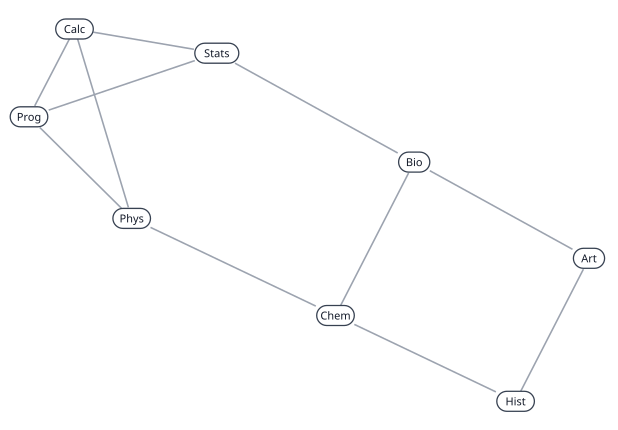

> 8 vertices, 11 edges

In [1]:
E = graph(["Calc" "Phys"; "Calc" "Stats"; "Calc" "Prog"; "Phys" "Chem"; "Phys" "Prog"; "Stats" "Bio"; "Chem" "Bio"; "Prog" "Stats"; "Hist" "Art"; "Art" "Bio"; "Hist" "Chem"])

Give every vertex a color (a time slot) so that joined vertices get different colors. The fewest colors that work is
the **chromatic number** $\chi(G)$.

{"Calc", "Phys", "Stats", "Prog", "Chem", "Bio", "Hist", "Art"}

> 8 vertices

[1, 2, 2, 3, 1, 3, 2, 1]

> 3 colors, the fewest possible; joined vertices get different colors

3

> 3 colors are enough for neighbours to differ, and fewer are not

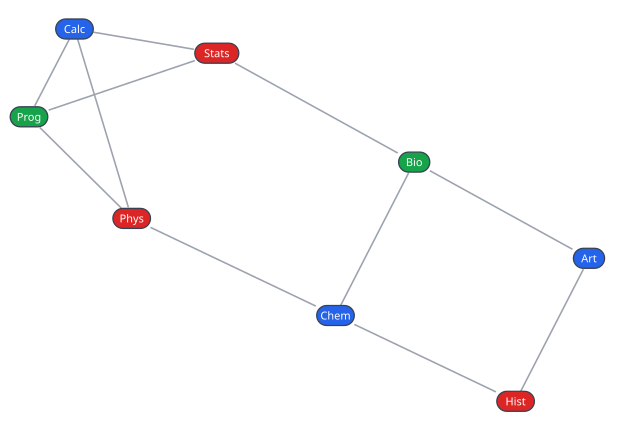

> vertices filled with their colors

In [2]:
vertices(E)
coloring(E)
chromatic(E)
draw(E, coloring(E))

Three slots suffice: slot 1 for Calc, Chem and Art; slot 2 for Phys, Stats and Hist; slot 3 for Prog and Bio. Fewer
is impossible, because Calc, Phys and Prog are joined to each other in a triangle, and a triangle needs three colors.

Finding $\chi(G)$ is hard in general (deciding whether 3 colors suffice is NP-complete). Galileo first colors greedily
(the DSATUR rule: next color the vertex with the most differently colored neighbours), then searches exhaustively for
a coloring with fewer colors, with a time budget. A large **clique** (vertices all joined to each other) gives a lower
bound, but not always the answer: an odd cycle needs 3 colors and has no triangle.

In [3]:
chromatic(cycle(5))
chromatic(wheel(5))
chromatic(wheel(6))

3

> 3 colors are enough for neighbours to differ, and fewer are not

4

> 4 colors are enough for neighbours to differ, and fewer are not

3

> 3 colors are enough for neighbours to differ, and fewer are not

A **wheel** is a cycle with a hub joined to every rim vertex. The hub needs a color of its own, so $\chi$ is one more
than for the rim: 4 for an odd rim, 3 for an even one. Any map of countries drawn in the plane can be colored with 4
colors so that neighbours differ: the **four color theorem**, conjectured in 1852 and proved by Appel and Haken in
1976 with a computer checking 1,936 cases. A wheel with a rim of 5 is a map (a country surrounded by five others) that
really needs all four.

**Try this.** Make `grid(4, 4)` and `complete(4)`. Predict their chromatic numbers, then check.

## 2. Counting colorings: the chromatic polynomial

How many ways are there to color a graph with $k$ colors? For a path of 3 vertices: $k$ choices for the first, then
$k - 1$ for each next one, so $k(k-1)^2$. In general the count is a polynomial in $k$, found by George Birkhoff in
1912 while attacking the four color problem. Galileo computes it by **deletion-contraction**: for an edge $e = uv$,
the colorings of $G - e$ are those where $u$ and $v$ differ (colorings of $G$) plus those where they agree
(colorings of $G / e$, with $u$ and $v$ merged), so

$$P(G, k) = P(G - e, k) - P(G / e, k).$$

In [4]:
chromaticpoly(path(3), k)
chromaticpoly(cycle(5), k)

k^3-2*k^2+k

> the number of ways to color the vertices with k colors so that joined vertices differ (deletion–contraction: P(G) = P(G - e) - P(G / e))

k^5-5*k^4+10*k^3-10*k^2+4*k

> the number of ways to color the vertices with k colors so that joined vertices differ (deletion–contraction: P(G) = P(G - e) - P(G / e))

For the 5-cycle this is $(k - 1)^5 - (k - 1)$; with 2 colors it gives $1 - 1 = 0$ (an odd cycle cannot be
2-colored), with 3 colors 30. The Petersen graph has 120 colorings with 3 colors:

In [5]:
chromaticpoly(cycle(5), 2)
chromaticpoly(cycle(5), 3)
chromaticpoly(petersen(), 3)

0

> the number of ways to color the vertices with k colors so that joined vertices differ (deletion–contraction: P(G) = P(G - e) - P(G / e))

30

> the number of ways to color the vertices with k colors so that joined vertices differ (deletion–contraction: P(G) = P(G - e) - P(G / e))

120

> the number of ways to color the vertices with k colors so that joined vertices differ (deletion–contraction: P(G) = P(G - e) - P(G / e))

**Try this.** Compute `chromaticpoly(complete(4), k)` and factor it. Why is the answer $k(k-1)(k-2)(k-3)$?

## 3. Doing things in order: topological sorting

Now the edges are arrows: "this course must come before that one".

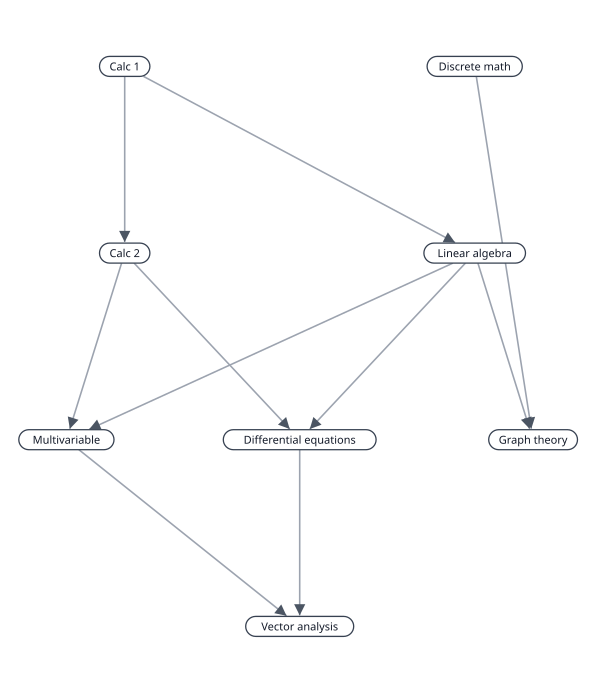

> 8 vertices, 10 directed edges

In [6]:
P = digraph(["Calc 1" "Calc 2"; "Calc 2" "Multivariable"; "Calc 1" "Linear algebra"; "Linear algebra" "Multivariable"; "Calc 2" "Differential equations"; "Linear algebra" "Differential equations"; "Multivariable" "Vector analysis"; "Differential equations" "Vector analysis"; "Discrete math" "Graph theory"; "Linear algebra" "Graph theory"])

A **topological order** lists the vertices so that every arrow points forward. Kahn's algorithm (1962) repeatedly
takes a vertex with no arrows coming in (a course with no open prerequisites), writes it down and removes it:

In [7]:
toposort(P)

{"Calc 1", "Calc 2", "Linear algebra", "Multivariable", "Differential equations", "Vector analysis", "Discrete math", "Graph theory"}

> every arrow points forward in this order (Kahn's algorithm, smaller vertices first)

Such an order exists exactly when the graph has no directed cycle; with a cycle, nobody could ever start. Build
systems, spreadsheets (which cell to recompute first) and package managers all sort this way.

**Try this.** Add the arrow `"Vector analysis" "Calc 1"` and run `toposort` again. What does `components` say about
the new graph?

## 4. Who is central? Betweenness and PageRank

In fifteenth-century Florence, the great families were tied together by marriages. Here are the marriage ties among
15 families, from the data that John Padgett and Christopher Ansell collected:

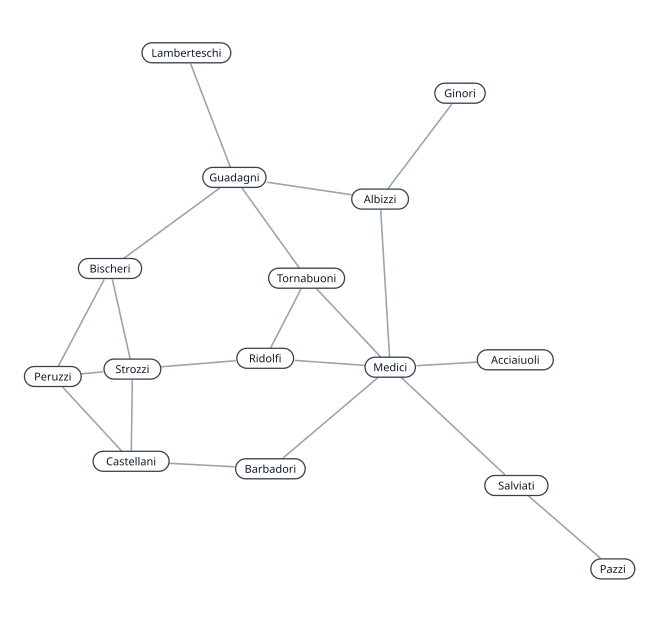

> 15 vertices, 20 edges

In [8]:
M = graph(["Acciaiuoli" "Medici"; "Castellani" "Peruzzi"; "Castellani" "Strozzi"; "Castellani" "Barbadori"; "Medici" "Barbadori"; "Medici" "Ridolfi"; "Medici" "Tornabuoni"; "Medici" "Albizzi"; "Medici" "Salviati"; "Salviati" "Pazzi"; "Peruzzi" "Strozzi"; "Peruzzi" "Bischeri"; "Strozzi" "Ridolfi"; "Strozzi" "Bischeri"; "Ridolfi" "Tornabuoni"; "Tornabuoni" "Guadagni"; "Albizzi" "Ginori"; "Albizzi" "Guadagni"; "Bischeri" "Guadagni"; "Guadagni" "Lamberteschi"])

The Strozzi were richer, and the Medici had only 6 marriage ties against 4 for the Strozzi and Guadagni. But count,
for each family, how many shortest paths between two other families pass through it. This is **betweenness
centrality**, Linton Freeman's measure (1977) of being a broker:

In [9]:
vertices(M)
degree(M)
centrality(M)

{"Acciaiuoli", "Medici", "Castellani", "Peruzzi", "Strozzi", "Barbadori", "Ridolfi", "Tornabuoni", "Albizzi", "Salviati", "Pazzi", "Bischeri", "Guadagni", "Ginori", "Lamberteschi"}

> 15 vertices

[1, 6, 3, 3, 4, 2, 3, 3, 3, 2, 1, 3, 4, 1, 1]

> the degrees add up to 40 = 2 × 20 edges, since each edge has two ends

[0, 47.5, 5, 2, 9.333333333333334, 8.5, 10.333333333333332, 8.333333333333332, 19.333333333333332, 13, 0, 9.5, 23.166666666666668, 0, 0]

> betweenness: for each vertex, how many shortest paths between other pairs pass through it (split evenly when there are several)

The Medici (second entry) score 47.5, twice the next family, the Guadagni with about 23. Of the 91 pairs of other
families, about half communicate most quickly through the Medici. Padgett and Ansell argued that this position, not
wealth, let Cosimo de' Medici take control of Florence in 1434.

A search engine faces a similar question on a directed graph: a link from page $i$ to page $j$ is a vote for $j$. Sergey
Brin and Larry Page's **PageRank** (1998) imagines a random surfer who follows a random link with probability
$d = 0.85$ and otherwise jumps to a random page; the rank of a page is the share of time the surfer spends there.

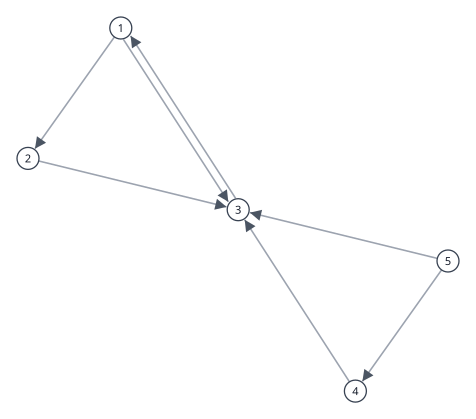

> 5 vertices, 7 directed edges

[0.35846806105144086, 0.18234892594685315, 0.386433013001706, 0.04275000000000001, 0.030000000000000006]

> the share of time a random surfer spends at each vertex, following a random edge with probability 0.85 and jumping anywhere otherwise; the shares add up to 1

In [10]:
W = digraph([1 2; 1 3; 2 3; 3 1; 4 3; 5 3; 5 4])
pagerank(W)

Page 3, which four pages link to, ranks highest. Page 1 comes second although only one page links to it, because that
page is the important page 3. The ranks add up to 1; they are the eigenvector of a matrix built from the links, found
by repeating the surfer's step until nothing changes.

**Try this.** Which family has the highest closeness, `centrality(M, "closeness")`? And what happens to the Medici's
betweenness if their marriage to the Albizzi had not taken place?

## 5. Random graphs and a sudden threshold

Paul Erdős and Alfréd Rényi asked in 1959: if each of the pairs among $n$ vertices is joined with probability $p$,
independently, what does the graph look like? `randgraph(n, p)` builds one. Let us estimate, for $n = 50$ and a
range of $p$, how often the random graph is connected:

In [11]:
seed(7);
n = 50; trials = 40;
for p in [0.02 0.04 0.06 0.08 0.1 0.12]
  c = 0;
  for k = 1:trials
    if isconnected(randgraph(n, p))
      c = c + 1;
    end
  end
  print(p, c / trials)
end

0.02 0
0.04 0
0.06 1/8
0.08 1/4
0.1 13/20
0.12 33/40

Within a small range of $p$ the graph goes from almost never connected to almost always. Erdős and Rényi proved that
the switch happens at $p = \ln(n)/n$, here $\ln 50 / 50 \approx 0.078$, and that it gets sharper as $n$ grows. The
reason: the last obstacle to connectivity is an isolated vertex, and the expected number of those, $n(1 - p)^{n-1}
\approx n e^{-pn}$, drops from large to small around $pn = \ln n$.

log(50)/50

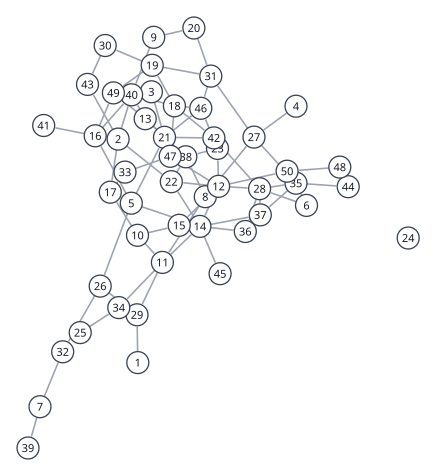

> the graph

In [12]:
log(50) / 50
seed(1); draw(randgraph(50, 0.05))

**Try this.** Repeat the experiment with $n = 200$ and $p$ from 0.01 to 0.04. Is the jump sharper? Where is it?

## Summary

* A coloring with $k$ colors is a schedule with $k$ time slots; $\chi(G)$ is the fewest. Cliques and odd cycles force
  colors; maps in the plane need at most 4.
* The chromatic polynomial counts colorings, by deletion-contraction $P(G) = P(G - e) - P(G / e)$.
* A directed graph without cycles can be put in topological order (Kahn's algorithm).
* Betweenness measures brokerage (the Medici); PageRank measures importance by votes from important pages.
* Random graphs become connected suddenly, at $p \approx \ln(n)/n$.

This is the end of the graphs path. The [index](README.md) lists the commands, and `help("graph")` describes each.

## Exercises

1. **Bipartite graphs.** Show that a graph with at least one edge has $\chi = 2$ exactly when it is bipartite. Check
   with `grid(3, 5)` and `hypercube(4)`.
2. **Trees.** Compute `chromaticpoly(path(5), k)` and `chromaticpoly(star(4), k)`. Both are trees with 5 vertices.
   Explain why every tree with $n$ vertices has $P = k(k-1)^{n-1}$.
3. **Course plan.** Add "Probability" with arrows from "Calc 2" to "Probability" and from "Probability" to
   "Graph theory". Where does it appear in `toposort`?
4. **PageRank by hand.** For `digraph([1 2; 2 1])`, what are the ranks, and why? What changes for
   `digraph([1 2; 2 3; 3 1])`?
5. **Giant component.** For $n = 100$, look at `components(randgraph(100, p))` for $p = 0.005, 0.01, 0.02$. How big is
   the largest component? (Erdős and Rényi: a giant component appears at $p = 1/n$.)

## Hints and answers

* **Section 1, Try this.** 2 for the grid (color it like a chessboard), 4 for `complete(4)`.
* **Section 2, Try this.** $k^4 - 6k^3 + 11k^2 - 6k = k(k-1)(k-2)(k-3)$: in a complete graph all colors differ, so
  $k$ choices, then $k - 1$, $k - 2$, $k - 3$.
* **Section 3, Try this.** Now `toposort` reports a directed cycle; `components` puts the six calculus-to-vector
  analysis courses in one strongly connected component.
* **Section 4, Try this.** The Medici again (0.56). Without the Albizzi tie the Medici's betweenness drops from 47.5
  to 41.5 and the Guadagni's rises to 38.5: the Medici stay first, but only just.
* **Section 5, Try this.** Sharper; the switch is near $\ln 200 / 200 \approx 0.026$.
* **Exercise 1.** Two colors are the two sides; both grids are bipartite, so `chromatic` gives 2.
* **Exercise 2.** Both are $k(k-1)^4$: color any vertex first ($k$ ways), then each further vertex has exactly one
  colored neighbour when you go outward from it ($k - 1$ ways).
* **Exercise 3.** After "Calc 2" and before "Graph theory".
* **Exercise 4.** 1/2 each: the surfer alternates. For the 3-cycle, 1/3 each, by symmetry.
* **Exercise 5.** Walk over the components with `for c in components(G) ... end` and keep the largest
  `length(c)`. At $p = 0.005$ and at $p = 0.01 = 1/n$ the largest component has only a handful of vertices; at
  $p = 0.02 = 2/n$ one component holds most of them (84 of 100 with `seed(2)`). The giant appears just past $1/n$.

## Sources

1. K. Appel and W. Haken, "Every planar map is four colorable", *Bulletin of the AMS* 82 (1976) 711–712.
2. G. D. Birkhoff, "A determinant formula for the number of ways of coloring a map", *Annals of Mathematics* 14
   (1912) 42–46.
3. D. Brélaz, "New methods to color the vertices of a graph", *Communications of the ACM* 22 (1979) 251–256 (DSATUR).
4. A. B. Kahn, "Topological sorting of large networks", *Communications of the ACM* 5 (1962) 558–562.
5. J. F. Padgett and C. K. Ansell, "Robust action and the rise of the Medici, 1400–1434", *American Journal of
   Sociology* 98 (1993) 1259–1319.
6. L. C. Freeman, "A set of measures of centrality based on betweenness", *Sociometry* 40 (1977) 35–41.
7. S. Brin and L. Page, "The anatomy of a large-scale hypertextual web search engine", *Computer Networks and ISDN
   Systems* 30 (1998) 107–117.
8. P. Erdős and A. Rényi, "On random graphs I", *Publicationes Mathematicae Debrecen* 6 (1959) 290–297.